# SARIMA thuần cho Pmax (mô hình so sánh)

Notebook đọc kết quả do `sarima.py` tạo ra (`data/sarima_*.csv`, `models/sarima_params.json`) và phân tích chúng. Báo cáo: `docs/SARIMA.md`; so sánh với mô hình chính: `docs/Comparison.md`.

Chạy lại:
```
python sarima.py
jupyter nbconvert --to notebook --execute --inplace notebooks/03_sarima.ipynb
```

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.stattools import acf, pacf

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import sarima as SA
import train as T

FIG = ROOT / "reports" / "figures"
pd.set_option("display.width", 160)
C = {"s1": "#2a78d6", "s2": "#eb6834", "s3": "#1baf7a", "ink": "#0b0b0b", "ink2": "#52514e", "muted": "#898781",
     "grid": "#e1e0d9", "axis": "#c3c2b7", "surface": "#fcfcfb", "band2": "#f6d3c4"}
plt.rcParams.update({
    "font.family": "Segoe UI", "font.size": 10,
    "figure.facecolor": C["surface"], "axes.facecolor": C["surface"], "savefig.facecolor": C["surface"],
    "axes.edgecolor": C["axis"], "axes.labelcolor": C["ink2"], "axes.titlecolor": C["ink"],
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": C["muted"], "ytick.color": C["muted"], "text.color": C["ink"],
    "lines.linewidth": 1.5, "legend.frameon": False,
})

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

y = SA.load_series()
bt = pd.read_csv(ROOT / "data" / "sarima_backtest.csv", parse_dates=["date"]).set_index("date")
met = pd.read_csv(ROOT / "data" / "sarima_metrics.csv")
dm = pd.read_csv(ROOT / "data" / "sarima_dm.csv")
val = pd.read_csv(ROOT / "data" / "sarima_validation.csv")
P = json.loads((ROOT / "models" / "sarima_params.json").read_text(encoding="utf-8"))
MAIN = "ensemble (mô hình chính)"
print("Bậc được chọn: SARIMA", tuple(P["order"]), tuple(P["seasonal_order"]))

Bậc được chọn: SARIMA (2, 0, 1) (1, 1, 1, 7)


## 1. Kiểm định tính dừng (ADF)

H₀: chuỗi có nghiệm đơn vị (không dừng). p < 0,05 thì bác bỏ H₀, tức chuỗi dừng.

In [2]:
display(pd.DataFrame(P["adf"]).round(4))

,chuỗi,thành phần tất định,ADF,ADF p,KPSS,KPSS p,n
0,y (gốc),hằng số,-3.0372,0.0316,4.1450,0.01,1187
1,y (gốc),hằng số + xu hướng,-6.3338,0.0000,0.1109,0.10,1188
2,Δy (sai phân bậc 1),hằng số,-10.5932,0.0000,0.0962,0.10,1176
3,Δ₇y (sai phân mùa),hằng số,-9.2979,0.0000,0.0154,0.10,1165
4,Δ Δ₇y (cả hai),hằng số,-13.9604,0.0000,0.0069,0.10,1145


## 2. ACF và PACF của chuỗi sai phân mùa Δ₇Pmax

Đây là chuỗi mà phần ARMA của mô hình cuối (d = 0, D = 1) làm việc trên đó. Dùng để gợi ý và kiểm tra bậc.

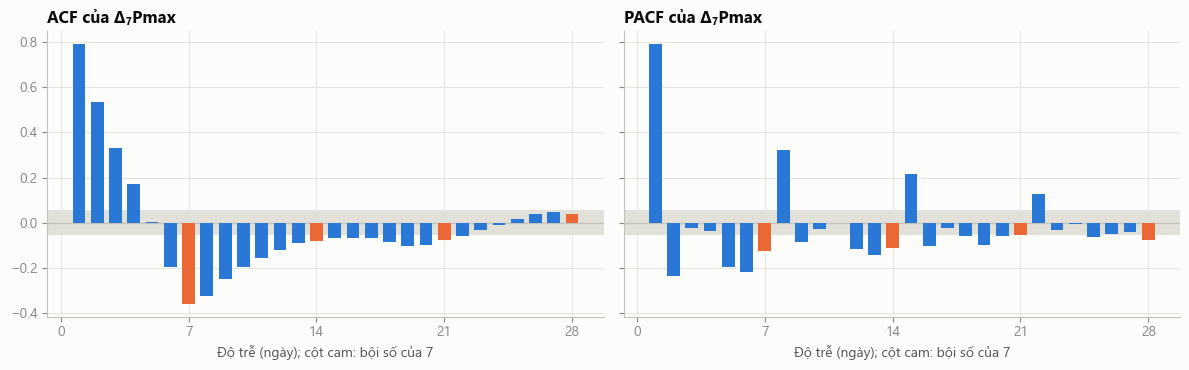

      ACF   PACF
1   0.790  0.790
2   0.536 -0.235
3   0.329 -0.025
7  -0.359 -0.127
14 -0.082 -0.113


In [3]:
z = y.diff(SA.S).dropna()
lags = 28
a, pa = acf(z, nlags=lags), pacf(z, nlags=lags, method="ywm")
ci = 1.96 / np.sqrt(len(z))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, v, title in [(axes[0], a, "ACF"), (axes[1], pa, "PACF")]:
    k = np.arange(1, lags + 1)
    ax.axhspan(-ci, ci, color=C["grid"], lw=0, zorder=1)
    ax.bar(k, v[1:], width=0.7, color=[C["s2"] if i % 7 == 0 else C["s1"] for i in k], zorder=3)
    ax.axhline(0, color=C["axis"], lw=1)
    ax.set_xticks(range(0, lags + 1, 7))
    ax.set_title(f"{title} của Δ₇Pmax")
    ax.set_xlabel("Độ trễ (ngày); cột cam: bội số của 7")
fig.tight_layout()
save(fig, "12_sarima_acf_pacf")
print(pd.DataFrame({"ACF": a[[1, 2, 3, 7, 14]], "PACF": pa[[1, 2, 3, 7, 14]]}, index=[1, 2, 3, 7, 14]).round(3))

## 3. Chọn bậc trên tập kiểm định (11/11/2024 → 10/11/2025)

In [4]:
v = val.copy()
v["mô hình"] = v.apply(lambda r: "SARIMA({},{},{})({},{},{})7".format(*[int(r[k]) for k in "pdqPDQ"]), axis=1)
display(v[["mô hình", "MAPE_valid", "mean_aic", "months_failed", "months_not_converged"]].head(10).round(3))
print("Tệ nhất:", v.iloc[-1]["mô hình"], round(v.iloc[-1]["MAPE_valid"], 3))

,mô hình,MAPE_valid,mean_aic,months_failed,months_not_converged
0,"SARIMA(2,0,1)(1,1,1)7",4.093,11707.530,0,0
1,"SARIMA(1,0,0)(1,1,1)7",4.133,11706.476,0,0
2,"SARIMA(1,0,1)(1,1,1)7",4.136,11708.056,0,0
3,"SARIMA(2,0,0)(1,1,1)7",4.137,11708.079,0,0
4,"SARIMA(1,0,0)(0,1,1)7",4.147,11705.113,0,0
5,"SARIMA(1,0,1)(0,1,1)7",4.152,11706.817,0,0
6,"SARIMA(2,0,0)(0,1,1)7",4.152,11706.836,0,0
7,"SARIMA(2,0,1)(0,1,1)7",4.157,11706.832,0,0
8,"SARIMA(1,0,2)(1,1,1)7",4.157,11709.521,0,0
9,"SARIMA(1,0,2)(0,1,1)7",4.171,11708.079,0,0


Tệ nhất: SARIMA(1,1,2)(1,1,1)7 12.257


## 4. Mô hình cuối: tham số và chẩn đoán phần dư

Huấn luyện trên toàn bộ dữ liệu đến 10/11/2026, chỉ để báo cáo tham số. Kiểm định Ljung–Box: H₀ là phần dư không tự tương quan.

In [5]:
f = P["final_fit"]
par = pd.DataFrame({"hệ số": f["params"], "sai số chuẩn": f["bse"]})
par["z"] = par["hệ số"] / par["sai số chuẩn"]
display(par.round(4))
print("AIC", round(f["aic"], 1), "BIC", round(f["bic"], 1))
display(pd.DataFrame(f["ljung_box"]).T.round(4))

,hệ số,sai số chuẩn,z
ar.L1,7.453000e-01,0.2175,3.4259
ar.L2,9.420000e-02,0.1953,0.4823
ma.L1,2.231000e-01,0.2164,1.0308
ar.S.L7,5.440000e-02,0.0302,1.7990
ma.S.L7,-8.645000e-01,0.0161,-53.8081
sigma2,3.293955e+06,66812.5597,49.3014


AIC 21556.7 BIC 21587.3


,lb_stat,lb_pvalue
7,10.8499,0.1453
14,16.6689,0.2743


## 5. Kết quả trên tập test (11/11/2025 → 10/11/2026)

Mọi mô hình được chấm trên **cùng một tập ngày**.

In [6]:
order = ["lag2", "lag7", "mean_lag7_28", "clean_base", "sarima", MAIN]
segs = ["tất cả", "ngày thường", "lễ/Tết", "nắng nóng (top 10% Tmax)"]
tab = met.pivot_table(index="model", columns="segment", values="MAPE").reindex(order)[segs].round(2)
allm = met[met.segment == "tất cả"].set_index("model").reindex(order)
tab["MAE (MW)"] = allm["MAE"].round(0)
tab["RMSE (MW)"] = allm["RMSE"].round(0)
tab["n"] = allm["n"]
display(tab)
display(dm.round(4))

segment,tất cả,ngày thường,lễ/Tết,nắng nóng (top 10% Tmax),MAE (MW),RMSE (MW),n
model,,,,,,,
lag2,7.08,6.62,13.55,6.11,3282.0,4355.0,329
lag7,5.67,4.16,26.65,6.45,2560.0,4178.0,329
mean_lag7_28,5.12,3.74,24.44,7.37,2270.0,3745.0,329
clean_base,4.46,2.92,25.86,6.64,1934.0,3476.0,329
sarima,3.71,2.90,15.04,4.30,1684.0,2647.0,329
ensemble (mô hình chính),2.12,1.86,5.71,2.71,993.0,1368.0,329


,sarima vs,DM,p_value,n
0,lag2,-9.6709,0.0000,329
1,lag7,-4.6043,0.0000,329
2,mean_lag7_28,-3.4033,0.0007,329
3,clean_base,-1.8471,0.0656,329
4,ensemble (mô hình chính),5.2133,0.0000,329


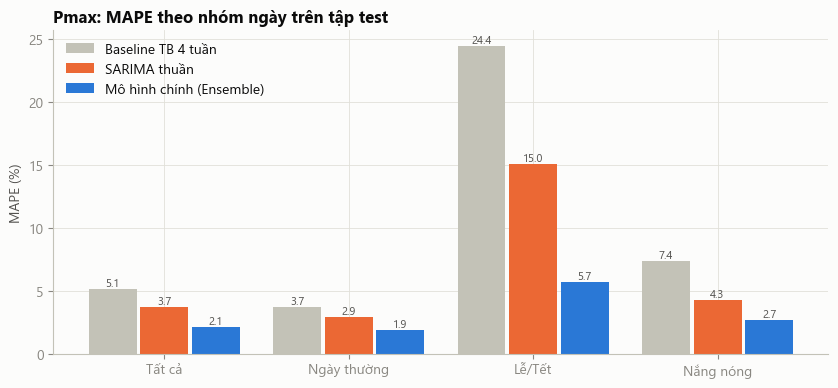

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.2))
show = [("mean_lag7_28", "Baseline TB 4 tuần", C["axis"]), ("sarima", "SARIMA thuần", C["s2"]), (MAIN, "Mô hình chính (Ensemble)", C["s1"])]
m = met.set_index(["model", "segment"])["MAPE"]
x = np.arange(len(segs)); w = 0.26
for i, (k, lab, c) in enumerate(show):
    vals = [m[(k, s)] for s in segs]
    ax.bar(x + (i - 1) * (w + 0.02), vals, width=w, color=c, label=lab)
    for xi, vi in zip(x, vals):
        ax.annotate(f"{vi:.1f}", (xi + (i - 1) * (w + 0.02), vi), xytext=(0, 2), textcoords="offset points",
                    ha="center", fontsize=8, color=C["ink2"])
ax.set_xticks(x, ["Tất cả", "Ngày thường", "Lễ/Tết", "Nắng nóng"])
ax.set_ylabel("MAPE (%)")
ax.set_title("Pmax: MAPE theo nhóm ngày trên tập test")
ax.legend(loc="upper left")
save(fig, "13_sarima_mape_by_segment")

## 6. Dự báo theo thời gian

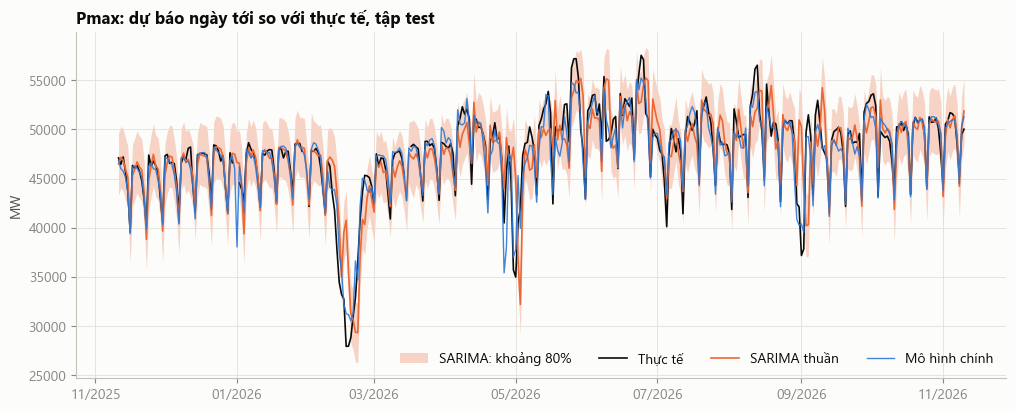

Độ phủ khoảng 80% của SARIMA: 86.1% (dưới P10 7.0%, trên P90 7.0%); độ rộng TB 13.3% của y


,SARIMA,Mô hình chính,TB 4 tuần
date,,,
11/2025,1.58,0.94,1.05
12/2025,1.49,1.10,1.90
01/2026,1.35,1.09,1.42
02/2026,10.07,3.89,19.02
03/2026,1.81,1.26,9.58
04/2026,4.05,3.18,5.32
05/2026,6.62,3.79,8.26
06/2026,4.15,2.13,3.46
07/2026,2.97,2.27,5.04


In [8]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.fill_between(bt.index, bt["sarima_p10"], bt["sarima_p90"], color=C["band2"], lw=0, label="SARIMA: khoảng 80%")
ax.plot(bt.index, bt["y"], color=C["ink"], lw=1.2, label="Thực tế")
ax.plot(bt.index, bt["sarima"], color=C["s2"], lw=1.2, label="SARIMA thuần")
ax.plot(bt.index, bt[MAIN], color=C["s1"], lw=1.0, alpha=0.9, label="Mô hình chính")
ax.set_ylabel("MW")
ax.set_title("Pmax: dự báo ngày tới so với thực tế, tập test")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
ax.legend(loc="lower right", ncol=4)
save(fig, "14_sarima_backtest")

c = bt.dropna(subset=["y", "sarima_p10"])
inside = (c["y"] >= c["sarima_p10"]) & (c["y"] <= c["sarima_p90"])
print(f"Độ phủ khoảng 80% của SARIMA: {inside.mean():.1%} (dưới P10 {(c.y < c.sarima_p10).mean():.1%}, trên P90 {(c.y > c.sarima_p90).mean():.1%}); "
      f"độ rộng TB {((c.sarima_p90 - c.sarima_p10) / c.y).mean():.1%} của y")

d = bt[bt["common"]]
ape = lambda col: (d[col] - d["y"]).abs() / d["y"] * 100
mon = pd.DataFrame({"SARIMA": ape("sarima"), "Mô hình chính": ape(MAIN), "TB 4 tuần": ape("mean_lag7_28")}).resample("MS").mean().round(2)
mon.index = mon.index.strftime("%m/%Y")
display(mon)

## 7. Tết 2026

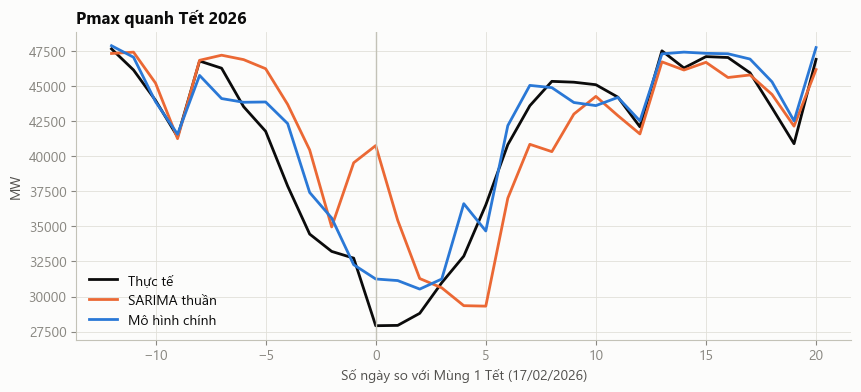

MAPE Tết (−10 → +15): {'mean_lag7_28': 20.23, 'sarima': 9.07, 'ensemble (mô hình chính)': 4.13}


In [9]:
d = bt[bt["tet_offset"].between(-12, 20)]
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(d["tet_offset"], d["y"], color=C["ink"], lw=2, label="Thực tế")
ax.plot(d["tet_offset"], d["sarima"], color=C["s2"], lw=2, label="SARIMA thuần")
ax.plot(d["tet_offset"], d[MAIN], color=C["s1"], lw=2, label="Mô hình chính")
ax.axvline(0, color=C["axis"], lw=1)
ax.set_xlabel("Số ngày so với Mùng 1 Tết (17/02/2026)")
ax.set_ylabel("MW")
ax.set_title("Pmax quanh Tết 2026")
ax.legend(loc="lower left")
save(fig, "15_sarima_tet_2026")
w = bt[bt["tet_offset"].between(-10, 15)].dropna(subset=["y"])
print("MAPE Tết (−10 → +15):", {k: round(T.mape(w["y"], w[k]), 2) for k in ["mean_lag7_28", "sarima", MAIN]})

## 8. Sau kỳ nghỉ: SARIMA có tiếp tục dự báo thấp không?

Ngày thường nằm 1–7 ngày sau ngày lễ/Tết cuối cùng. Sai số có dấu: âm nghĩa là dự báo thấp hơn thực tế.

TB 4 tuần                    SARIMA             Mô hình chính        số ngày
                   sai số TB có dấu % MAPE % sai số TB có dấu % MAPE % sai số TB có dấu % MAPE %        
days_after_special                                                                                      
1.0                              9.20   9.20             -10.52  10.52               3.05   4.82       3
2.0                              1.00   6.33             -10.37  12.70              -0.65   3.85       4
3.0                             -2.51   4.27              -4.73   4.73              -2.97   2.97       4
4.0                             -1.92   3.37              -0.23   1.50              -0.77   2.49       4
5.0                             -4.13   4.95              -2.04   2.04              -2.05   2.30       4
6.0                             -9.68   9.68              -6.87   6.87              -2.60   2.98       3
7.0                             -7.59   7.59              -2.72   2.72              -0.62   2.04       3

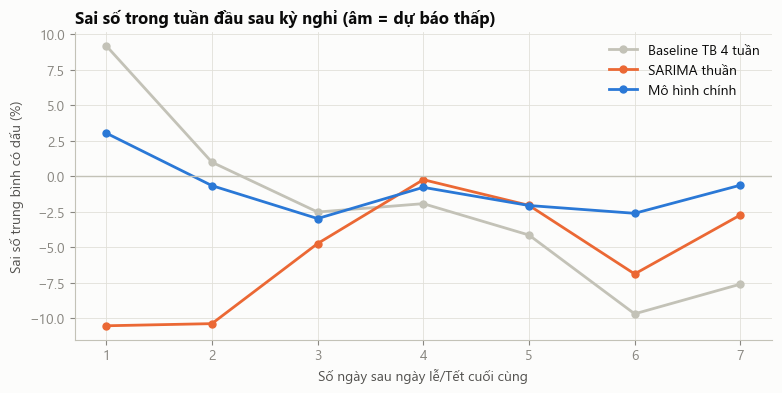

In [10]:
d = bt.dropna(subset=["days_after_special", "y"])
d = d[d["common"]]
rows = {}
for k, lab in [("mean_lag7_28", "TB 4 tuần"), ("sarima", "SARIMA"), (MAIN, "Mô hình chính")]:
    e = (d[k] - d["y"]) / d["y"] * 100
    rows[(lab, "sai số TB có dấu %")] = e.groupby(d["days_after_special"]).mean()
    rows[(lab, "MAPE %")] = e.abs().groupby(d["days_after_special"]).mean()
post = pd.DataFrame(rows).round(2)
post["số ngày"] = d.groupby("days_after_special").size()
display(post)

fig, ax = plt.subplots(figsize=(9, 4))
for key, lab, c in [("TB 4 tuần", "Baseline TB 4 tuần", C["axis"]), ("SARIMA", "SARIMA thuần", C["s2"]), ("Mô hình chính", "Mô hình chính", C["s1"])]:
    v = post[(key, "sai số TB có dấu %")]
    ax.plot(v.index, v.values, marker="o", ms=5, color=c, lw=2, label=lab)
ax.axhline(0, color=C["axis"], lw=1)
ax.set_xlabel("Số ngày sau ngày lễ/Tết cuối cùng")
ax.set_ylabel("Sai số trung bình có dấu (%)")
ax.set_title("Sai số trong tuần đầu sau kỳ nghỉ (âm = dự báo thấp)")
ax.legend(loc="upper right")
save(fig, "16_sarima_post_holiday")

## 9. Lần chạy 1 (d = 1 cố định) và lần chạy 2 (chọn d trên tập kiểm định)

Lần chạy 1 cố định sai phân bậc 1 (d = 1) trước khi xem kết quả kiểm định tính dừng. Hệ số MA(1) của mô hình đó ≈ −0,999, dấu hiệu sai phân thừa; ADF có xu hướng và KPSS cho thấy chuỗi dừng quanh xu hướng. Lần chạy 2 đưa d ∈ {0, 1} vào lưới và chọn lại **chỉ dựa trên tập kiểm định**. Kết quả lần 1 được lưu trong `data/sarima_run1/`.

In [11]:
R1 = ROOT / "data" / "sarima_run1"
p1 = json.loads((R1 / "sarima_params.json").read_text(encoding="utf-8"))
m1 = pd.read_csv(R1 / "sarima_metrics.csv")
rows = []
for name, pp, mm in [("Lần 1: d = 1 cố định", p1, m1), ("Lần 2: chọn d trên kiểm định", P, met)]:
    s = mm[mm.model == "sarima"].set_index("segment")["MAPE"]
    rows.append({"lần chạy": name, "bậc": f"{tuple(pp['order'])}{tuple(pp['seasonal_order'])}",
                 "MAPE kiểm định": round(pp["valid_mape"], 3), "MAPE test (tất cả)": round(s["tất cả"], 2),
                 "test: ngày thường": round(s["ngày thường"], 2), "test: lễ/Tết": round(s["lễ/Tết"], 2),
                 "ma.L1 (mô hình cuối)": pp["final_fit"]["params"].get("ma.L1")})
display(pd.DataFrame(rows).set_index("lần chạy"))

,bậc,MAPE kiểm định,MAPE test (tất cả),test: ngày thường,test: lễ/Tết,ma.L1 (mô hình cuối)
lần chạy,,,,,,
Lần 1: d = 1 cố định,"(1, 1, 1)(1, 1, 1, 7)",4.186,3.79,3.04,14.23,-0.998884
Lần 2: chọn d trên kiểm định,"(2, 0, 1)(1, 1, 1, 7)",4.093,3.71,2.90,15.04,0.223057


## 10. Bậc thang sai số: từ baseline đến mô hình chính

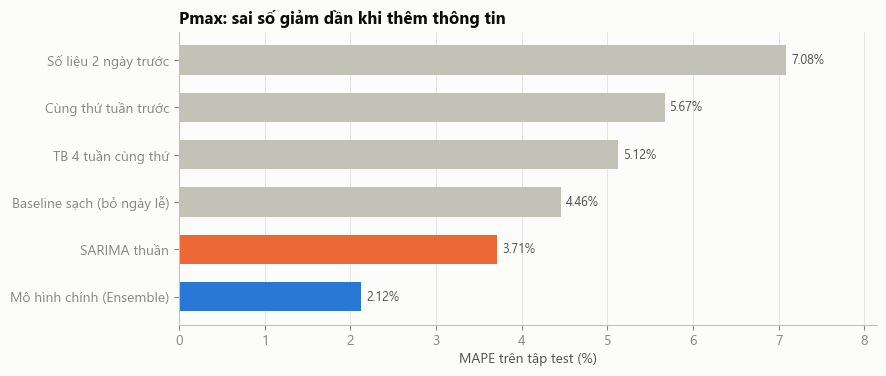

In [12]:
steps = [("lag2", "Số liệu 2 ngày trước"), ("lag7", "Cùng thứ tuần trước"), ("mean_lag7_28", "TB 4 tuần cùng thứ"),
         ("clean_base", "Baseline sạch (bỏ ngày lễ)"), ("sarima", "SARIMA thuần"), (MAIN, "Mô hình chính (Ensemble)")]
vals = [met[(met.model == k) & (met.segment == "tất cả")]["MAPE"].iloc[0] for k, _ in steps]
colors = [C["axis"]] * 4 + [C["s2"], C["s1"]]
fig, ax = plt.subplots(figsize=(9, 3.8))
yy = np.arange(len(steps))[::-1]
ax.barh(yy, vals, color=colors, height=0.62)
for yi, v in zip(yy, vals):
    ax.annotate(f"{v:.2f}%", (v, yi), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9, color=C["ink2"])
ax.set_yticks(yy, [lab for _, lab in steps])
ax.set_xlabel("MAPE trên tập test (%)")
ax.set_title("Pmax: sai số giảm dần khi thêm thông tin")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, max(vals) * 1.15)
save(fig, "17_error_ladder")

## 11. Những ngày SARIMA sai nhiều nhất

In [13]:
d = bt[bt["common"]].copy()
d["sai số SARIMA %"] = (d["sarima"] - d["y"]) / d["y"] * 100
d["sai số chính %"] = (d[MAIN] - d["y"]) / d["y"] * 100
cal = pd.read_csv(ROOT / "data" / "calendar.csv", parse_dates=["date"]).set_index("date")
worst = d.reindex(d["sai số SARIMA %"].abs().sort_values(ascending=False).index).head(12).join(cal[["dow", "holiday_name"]])
display(worst[["y", "sarima", "sai số SARIMA %", MAIN, "sai số chính %", "dow", "holiday_name", "tet_offset", "days_after_special"]].round(1))
print(f"Tỉ lệ ngày SARIMA sai > 5%: {(d['sai số SARIMA %'].abs() > 5).mean():.1%}; mô hình chính: {(d['sai số chính %'].abs() > 5).mean():.1%}")
for lim in (1, 2, 3, 5):
    print(f"  sai số < {lim}%: SARIMA {(d['sai số SARIMA %'].abs() < lim).mean():.1%}, mô hình chính {(d['sai số chính %'].abs() < lim).mean():.1%}")

,y,sarima,sai số SARIMA %,ensemble (mô hình chính),sai số chính %,dow,holiday_name,tet_offset,days_after_special
date,,,,,,,,,
2026-02-17,27919.3,40751.0,46.0,31248.7,11.9,1,Tết Nguyên Đán,0,NaN
2026-09-01,37167.0,50288.8,35.3,40389.4,8.7,1,Quốc khánh,-158,NaN
2026-04-30,35700.0,48173.0,34.9,36990.8,3.6,3,Ngày Chiến thắng,72,NaN
2026-05-01,34969.1,45001.2,28.7,37769.1,8.0,4,Ngày Quốc tế Lao động,73,NaN
2026-02-18,27942.8,35427.2,26.8,31135.2,11.4,2,Mùng hai Tết Nguyên Đán,1,NaN
2026-05-03,41923.3,32186.8,-23.2,39939.9,-4.7,6,NaN,75,2.0
2026-09-04,51480.9,40303.1,-21.7,49280.1,-4.3,4,NaN,-155,2.0
2026-08-31,42101.8,50954.6,21.0,40245.3,-4.4,0,Ngày nghỉ (thay cho ngày 22/08/2026),-159,NaN
2026-02-16,32732.5,39528.7,20.8,32265.0,-1.4,0,Giao thừa Tết Nguyên Đán,-1,NaN


Tỉ lệ ngày SARIMA sai > 5%: 22.2%; mô hình chính: 6.1%
  sai số < 1%: SARIMA 26.4%, mô hình chính 35.0%
  sai số < 2%: SARIMA 48.3%, mô hình chính 60.2%
  sai số < 3%: SARIMA 63.2%, mô hình chính 76.6%
  sai số < 5%: SARIMA 77.8%, mô hình chính 93.9%
